# Customer Churn Prediction Using Machine Learning

## Objective
Analyze customer churn behavior and compare machine-learning models to predict whether a customer is likely to churn. This notebook covers data cleaning, exploratory data analysis, preprocessing, model training, evaluation, model comparison, and business recommendations.

**Important correction:** preprocessing is fitted only on the training data through scikit-learn pipelines. This prevents information from the test set leaking into model training.

## 1. Data Loading

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay
)

sns.set_theme(style="whitegrid")

# Keep Telco-Customer-Churn.csv in the same folder as this notebook.
df = pd.read_csv("Telco-Customer-Churn.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Data Cleaning and Preprocessing

In [3]:
df.info()
display(df.isna().sum().sort_values(ascending=False).head(10))

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

customerID         0
gender             0
SeniorCitizen      0
Partner            0
Dependents         0
tenure             0
PhoneService       0
MultipleLines      0
InternetService    0
OnlineSecurity     0
dtype: int64

In [4]:
# TotalCharges is often stored as text; convert invalid/blank values to NaN.
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

# Remove the identifier because it does not provide a useful generalizable signal.
if "customerID" in df.columns:
    df = df.drop(columns=["customerID"])

# Confirm target values and inspect missing values after conversion.
print("Target values:", df["Churn"].value_counts(dropna=False).to_dict())
print("\nMissing values after conversion:")
display(df.isna().sum().sort_values(ascending=False).head(10))

Target values: {'No': 5174, 'Yes': 1869}

Missing values after conversion:


TotalCharges      11
gender             0
Partner            0
SeniorCitizen      0
Dependents         0
tenure             0
MultipleLines      0
PhoneService       0
OnlineSecurity     0
OnlineBackup       0
dtype: int64

## 3. Exploratory Data Analysis

Churn
No     73.46
Yes    26.54
Name: Percentage, dtype: float64

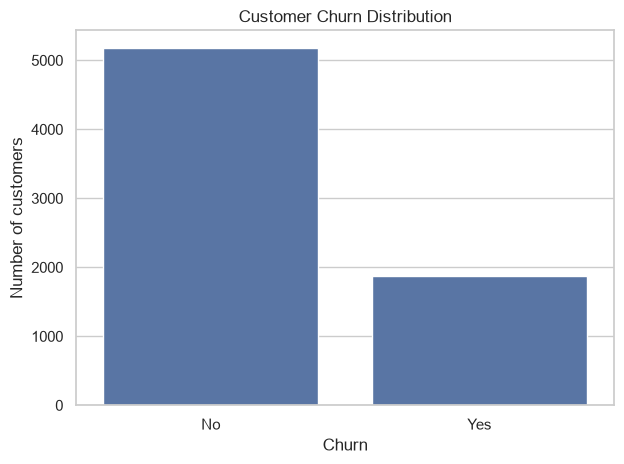

In [5]:
# Churn distribution
churn_pct = (df["Churn"].value_counts(normalize=True) * 100).round(2)
display(churn_pct.rename("Percentage"))

ax = sns.countplot(data=df, x="Churn")
ax.set_title("Customer Churn Distribution")
ax.set_xlabel("Churn")
ax.set_ylabel("Number of customers")
plt.tight_layout()
plt.show()

Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


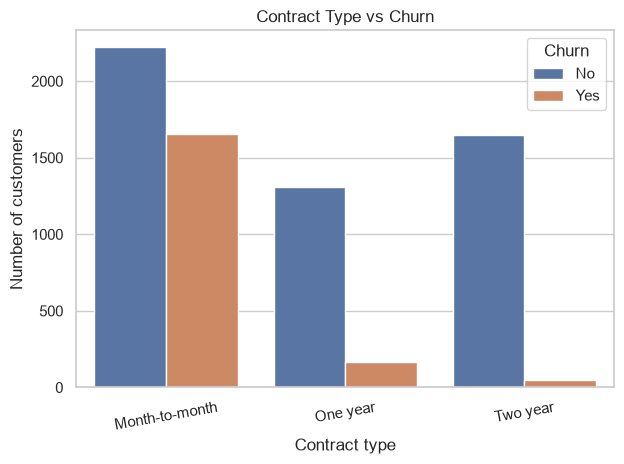

In [6]:
# Churn rate by contract type
contract_churn = pd.crosstab(df["Contract"], df["Churn"], normalize="index").mul(100).round(2)
display(contract_churn)

ax = sns.countplot(data=df, x="Contract", hue="Churn")
ax.set_title("Contract Type vs Churn")
ax.set_xlabel("Contract type")
ax.set_ylabel("Number of customers")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

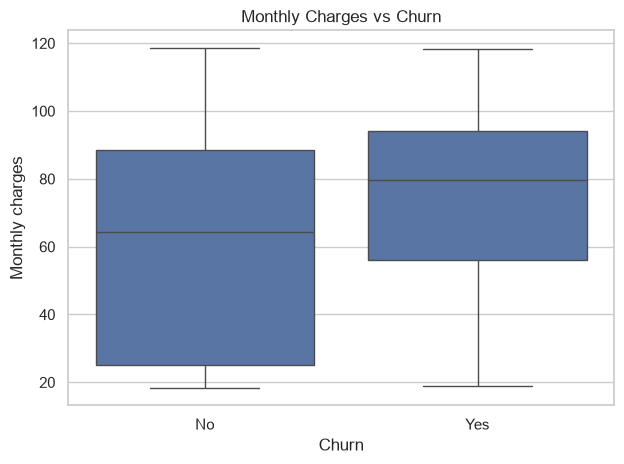

In [7]:
# Monthly charges by churn status
ax = sns.boxplot(data=df, x="Churn", y="MonthlyCharges")
ax.set_title("Monthly Charges vs Churn")
ax.set_xlabel("Churn")
ax.set_ylabel("Monthly charges")
plt.tight_layout()
plt.show()

## 4. Train-Test Split and Leakage-Safe Preprocessing
Split the data before fitting imputers, encoders, or scalers. Numeric features are imputed with their training-set median and standardized. Categorical features are imputed with their most frequent training-set value and one-hot encoded. The test set is only transformed, never used to fit preprocessing.

In [8]:
# Separate features and target
X = df.drop(columns=["Churn"]).copy()
y = df["Churn"].map({"No": 0, "Yes": 1})

if y.isna().any():
    raise ValueError("Unexpected values found in the Churn target. Check the source data.")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=["number"]).columns.tolist()

numeric_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_preprocessor, numeric_features),
    ("categorical", categorical_preprocessor, categorical_features)
])

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))
print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

Training rows: 5634
Test rows: 1409
Numeric features: 4
Categorical features: 15


## 5. Model Building
Both models use the same leakage-safe preprocessing. Logistic Regression benefits from scaled numeric features. Random Forest is trained through the same pipeline for a fair comparison.

In [9]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, random_state=42, class_weight="balanced"
    )
}

fitted_models = {}
predictions = {}
results = []

for model_name, estimator in models.items():
    model_pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])
    model_pipeline.fit(X_train, y_train)
    y_pred = model_pipeline.predict(X_test)

    fitted_models[model_name] = model_pipeline
    predictions[model_name] = y_pred
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0)
    })

comparison = pd.DataFrame(results).sort_values("F1 Score", ascending=False)
display(comparison.style.format({
    "Accuracy": "{:.2%}", "Precision": "{:.2%}",
    "Recall": "{:.2%}", "F1 Score": "{:.2%}"
}))

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,80.55%,65.72%,55.88%,60.40%
1,Random Forest,76.58%,55.21%,62.30%,58.54%


## 6. Model Evaluation


Logistic Regression
              precision    recall  f1-score   support

    No churn       0.85      0.89      0.87      1035
       Churn       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



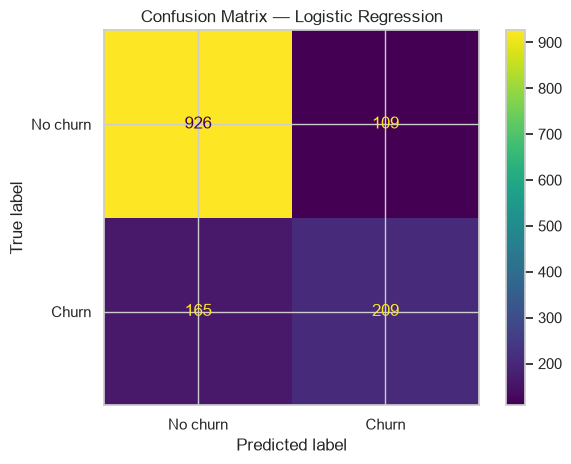


Random Forest
              precision    recall  f1-score   support

    No churn       0.86      0.82      0.84      1035
       Churn       0.55      0.62      0.59       374

    accuracy                           0.77      1409
   macro avg       0.70      0.72      0.71      1409
weighted avg       0.78      0.77      0.77      1409



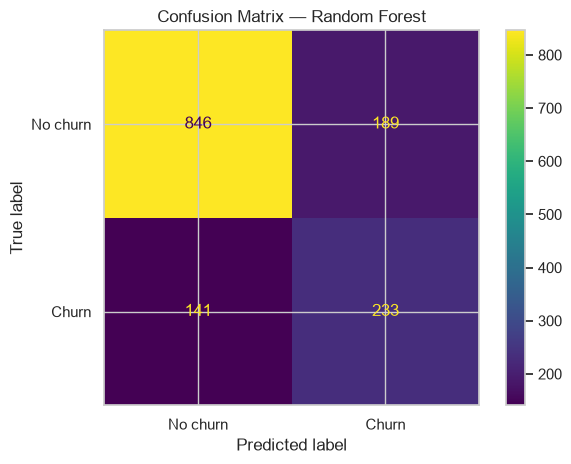

In [10]:
for model_name, y_pred in predictions.items():
    print(f"\n{'=' * 60}\n{model_name}\n{'=' * 60}")
    print(classification_report(
        y_test, y_pred, labels=[0, 1],
        target_names=["No churn", "Churn"], zero_division=0
    ))

    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred, labels=[0, 1],
        display_labels=["No churn", "Churn"], values_format="d"
    )
    plt.title(f"Confusion Matrix — {model_name}")
    plt.tight_layout()
    plt.show()

## 7. Model Comparison
The table above calculates all metrics directly from the current test-set predictions. Do not manually type or reuse metrics from an earlier run. For churn prevention, recall and F1 score for the churn class can be particularly important, because missed churners may represent lost revenue.

In [11]:
best_model_name = comparison.iloc[0]["Model"]
print("Model with the highest test-set F1 score:", best_model_name)
print("Its test-set metrics:")
display(comparison.loc[comparison["Model"] == best_model_name].style.format({
    "Accuracy": "{:.2%}", "Precision": "{:.2%}",
    "Recall": "{:.2%}", "F1 Score": "{:.2%}"
}))

Model with the highest test-set F1 score: Logistic Regression
Its test-set metrics:


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,80.55%,65.72%,55.88%,60.40%


## 8. Business Recommendations

Based on the exploratory patterns to investigate further:

- Encourage month-to-month customers to consider one-year or two-year contracts through suitable incentives.
- Review pricing and retention options for customers with high monthly charges.
- Promote the value of Online Security and Tech Support services where relevant.
- Prioritize early-tenure customers for onboarding and retention outreach.

These are recommendations to test, not proof that any single factor causes churn. Validate campaign impact with controlled experiments where possible.

## 9. Conclusion

This notebook compares Logistic Regression and Random Forest for customer churn prediction. Preprocessing is fitted on the training split only, and the metrics are recalculated from model predictions each time the notebook runs. The model with the strongest F1 score is surfaced automatically; final model selection should also consider churn recall, business costs, and validation on new data.